# Diseño de una Red Neuronal en Python con el dataset Titanic

## 1. Descarga del dataset Titanic
Descarga el archivo `train.csv` desde Kaggle Titanic dataset y colócalo en el directorio de trabajo.

## 2. Carga de datos en un DataFrame
Cargamos los datos y exploramos las primeras filas.

In [10]:
import pandas as pd
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Análisis exploratorio de los datos (EDA)
Inspeccionamos columnas, valores nulos, estadísticas y balance de clases.

In [11]:
# Ver columnas y valores nulos
print(df.info())
print(df.isnull().sum())
# Estadísticas descriptivas
display(df.describe())
# Balance de clases
print(df['Survived'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int6

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


## 4. Preprocesamiento de los datos
Eliminamos columnas innecesarias, imputamos nulos, codificamos variables categóricas y normalizamos numéricas.

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Eliminamos columnas irrelevantes
df = df.drop(['Name', 'Ticket', 'Cabin', 'PassengerId'], axis=1)
# Imputamos nulos en Age y Fare
imputer = SimpleImputer(strategy='median')
df['Age'] = imputer.fit_transform(df[['Age']])
df['Fare'] = imputer.fit_transform(df[['Fare']])
# Codificamos Sex y Embarked
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].fillna('S')
embarked_ohe = pd.get_dummies(df['Embarked'], prefix='Embarked')
df = pd.concat([df.drop('Embarked', axis=1), embarked_ohe], axis=1)
# Normalizamos Age y Fare
scaler = StandardScaler()
df[['Age', 'Fare']] = scaler.fit_transform(df[['Age', 'Fare']])

## 5. División de los datos en entrenamiento y prueba
Dividimos el dataset en 80% entrenamiento y 20% prueba.

In [13]:
from sklearn.model_selection import train_test_split
X = df.drop('Survived', axis=1)
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 6. Diseño de la red neuronal
Creamos una red neuronal con Keras: capa de entrada, capas ocultas con ReLU y salida con Sigmoid.

In [14]:
import tensorflow as tf
from tensorflow import keras
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenamiento del modelo
Entrenamos el modelo con 50 épocas y batch size 32, validando con el conjunto de prueba.

In [15]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test), verbose=1)

Epoch 1/50


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6461 - loss: 0.6234 - val_accuracy: 0.6536 - val_loss: 0.6348
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6643 - loss: 0.6085 - val_accuracy: 0.6536 - val_loss: 0.6228
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6840 - loss: 0.5939 - val_accuracy: 0.6648 - val_loss: 0.6093
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6994 - loss: 0.5797 - val_accuracy: 0.6760 - val_loss: 0.5960
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7205 - loss: 0.5649 - val_accuracy: 0.6872 - val_loss: 0.5832
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7261 - loss: 0.5503 - val_accuracy: 0.7095 - val_loss: 0.5708
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7360 - loss: 0.5360 - val_accuracy: 0.7318 - val_loss: 0.5572
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7458 - loss: 0.5209 - val_accuracy: 0.7486 - val_loss: 0.5412
Epo

## 8. Evaluación del modelo
Evaluamos la precisión en el conjunto de prueba.

In [16]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Precisión en el conjunto de prueba: {accuracy:.2f}')
print(f'Pérdida en el conjunto de prueba: {loss:.2f}')

Precisión en el conjunto de prueba: 0.82
Pérdida en el conjunto de prueba: 0.44


## 9. Visualización del rendimiento del modelo
Graficamos la precisión y la pérdida durante el entrenamiento.

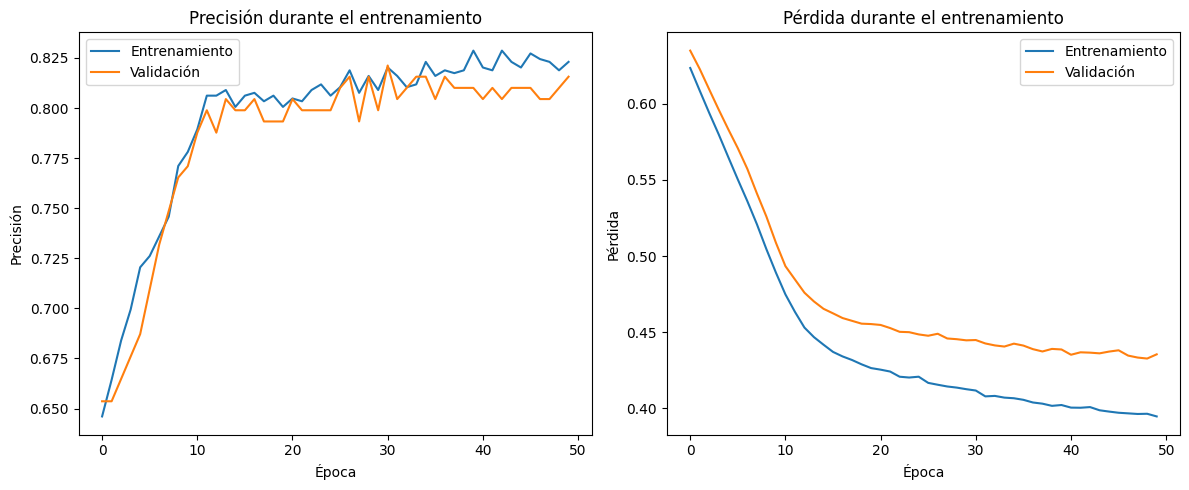

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Predicción sobre los datos de prueba
Realizamos predicciones y comparamos con las etiquetas reales.

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, log_loss

y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
print('Primeras predicciones:', y_pred[:10])
print('Etiquetas reales:', y_test.values[:10])

print('Exactitud:', accuracy_score(y_test, y_pred))
print('F1-score:', f1_score(y_test, y_pred, average='weighted'))
print('Log Loss:', log_loss(y_test, y_pred_prob))
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred, target_names=['No sobrevivió', 'Sobrevivió']))
print('Matriz de confusión:')
print(confusion_matrix(y_test, y_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Primeras predicciones: [0 0 0 0 1 1 1 0 0 0]
Etiquetas reales: [0 0 1 0 1 1 1 0 0 0]
Exactitud: 0.8156424581005587
F1-score: 0.809303701036959
Log Loss: 0.43548259498155584
Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.80      0.93      0.86       110
   Sobrevivió       0.85      0.64      0.73        69

     accuracy                           0.82       179
    macro avg       0.82      0.78      0.79       179
 weighted avg       0.82      0.82      0.81       179

Matriz de confusión:
[[102   8]
 [ 25  44]]
